In [91]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [92]:
data = pd.read_csv(r'C:\Users\kasim\Desktop\Projects\Breast Cancer Machine learning\seer_breast_cancer_clean.csv')

data.head()

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Regional Node Positive,Survival Months,Status
0,43,"Other (American Indian/AK Native, Asian/Pacifi...",Married (including common law),T2,N3,IIIC,Moderately differentiated; Grade II,Regional,40,Positive,Positive,19,11,1,Alive
1,47,"Other (American Indian/AK Native, Asian/Pacifi...",Married (including common law),T2,N2,IIIA,Moderately differentiated; Grade II,Regional,45,Positive,Positive,25,9,2,Alive
2,67,White,Married (including common law),T2,N1,IIB,Poorly differentiated; Grade III,Regional,25,Positive,Positive,4,1,2,Dead
3,46,White,Divorced,T1,N1,IIA,Moderately differentiated; Grade II,Regional,19,Positive,Positive,26,1,2,Dead
4,63,White,Married (including common law),T2,N2,IIIA,Moderately differentiated; Grade II,Regional,35,Positive,Positive,21,5,3,Dead


In [93]:
print(data.shape)
data.info()

(4024, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Age                     4024 non-null   int64 
 1   Race                    4024 non-null   object
 2   Marital Status          4024 non-null   object
 3   T Stage                 4024 non-null   object
 4   N Stage                 4024 non-null   object
 5   6th Stage               4024 non-null   object
 6   Grade                   4024 non-null   object
 7   A Stage                 4024 non-null   object
 8   Tumor Size              4024 non-null   int64 
 9   Estrogen Status         4024 non-null   object
 10  Progesterone Status     4024 non-null   object
 11  Regional Node Examined  4024 non-null   int64 
 12  Regional Node Positive  4024 non-null   int64 
 13  Survival Months         4024 non-null   int64 
 14  Status                  4024 non-null   objec

In [94]:
print(data.isnull().sum())
print(data.duplicated().sum())

Age                       0
Race                      0
Marital Status            0
T Stage                   0
N Stage                   0
6th Stage                 0
Grade                     0
A Stage                   0
Tumor Size                0
Estrogen Status           0
Progesterone Status       0
Regional Node Examined    0
Regional Node Positive    0
Survival Months           0
Status                    0
dtype: int64
1


In [95]:
data = data.drop_duplicates().reset_index(drop=True)
print(data.shape)


(4023, 15)


Descriptve Statistics

In [96]:
data.describe()

,Age,Tumor Size,Regional Node Examined,Regional Node Positive,Survival Months
count,4023.000000,4023.000000,4023.000000,4023.000000,4023.000000
mean,53.969923,30.477007,14.358439,4.158837,71.301765
std,8.963118,21.121253,8.100241,5.109724,22.923009
min,30.000000,1.000000,1.000000,1.000000,1.000000
25%,47.000000,16.000000,9.000000,1.000000,56.000000
50%,54.000000,25.000000,14.000000,2.000000,73.000000
75%,61.000000,38.000000,19.000000,5.000000,90.000000
max,69.000000,140.000000,61.000000,46.000000,107.000000


In [97]:
#Counts for categorical columns
data.describe(include='object')

for col in data.select_dtypes('object'):
    print(data[col].value_counts(), '\n')


#checking class balance 
print(data['Status'].value_counts(normalize=True))

#Numeric columns compared by outcome
data.groupby('Status').mean(numeric_only=True)


Race
White                                                        3412
Other (American Indian/AK Native, Asian/Pacific Islander)     320
Black                                                         291
Name: count, dtype: int64 

Marital Status
Married (including common law)    2642
Single (never married)             615
Divorced                           486
Widowed                            235
Separated                           45
Name: count, dtype: int64 

T Stage
T2    1786
T1    1602
T3     533
T4     102
Name: count, dtype: int64 

N Stage
N1    2731
N2     820
N3     472
Name: count, dtype: int64 

6th Stage
IIA     1304
IIB     1130
IIIA    1050
IIIC     472
IIIB      67
Name: count, dtype: int64 

Grade
Moderately differentiated; Grade II       2350
Poorly differentiated; Grade III          1111
Well differentiated; Grade I               543
Undifferentiated; anaplastic; Grade IV      19
Name: count, dtype: int64 

A Stage
Regional    3931
Distant       92
Name: count, dt

,Age,Tumor Size,Regional Node Examined,Regional Node Positive,Survival Months
Status,,,,,
Alive,53.756384,29.27238,14.238920,3.601409,75.946874
Dead,55.150974,37.13961,15.019481,7.241883,45.610390


In [98]:
%pip install scipy scikit-learn imbalanced-learn xgboost shap plotly lifelines

In [99]:
from scipy.stats import chi2_contingency

table = pd.crosstab(data['T Stage'], data['Status'])
result = chi2_contingency(table)
print('p-value:', result[1])

p-value: 2.9606888213998393e-22


In [100]:
from scipy.stats import mannwhitneyu 

alive = data[data['Status'] == 'Alive']['Tumor Size']
dead = data[data['Status'] == 'Dead']['Tumor Size']

result = mannwhitneyu(alive, dead)
print('p-value:', result[1])

p-value: 5.098613377306892e-19


Visualisation

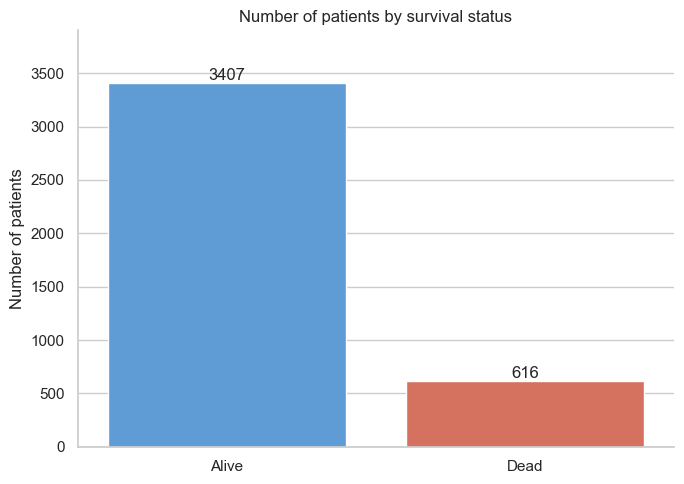

In [101]:
#Class Balance
sns.set_theme(style='whitegrid')

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=data, x='Status', hue='Status', palette={'Alive': '#4C9BE8', 'Dead': '#E8634C'}, legend=False)

for bars in ax.containers:
    ax.bar_label(bars)

plt.title('Number of patients by survival status')
plt.xlabel('')
plt.ylabel('Number of patients')
plt.ylim(0, 3900)
sns.despine()
plt.tight_layout()
plt.show()

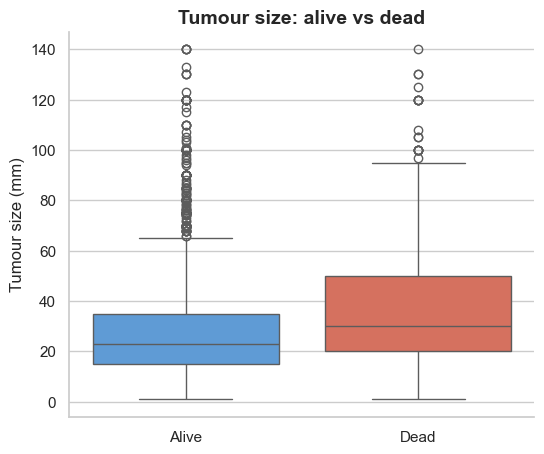

In [102]:
#Tumour size: alive vs dead

plt.figure(figsize=(6, 5))

sns.boxplot(data=data, x='Status', y='Tumor Size', hue='Status', palette={'Alive': '#4C9BE8', 'Dead': '#E8634C'}, legend=False)

plt.title('Tumour size: alive vs dead', fontsize=14, fontweight='bold')
plt.ylabel('Tumour size (mm)')
plt.xlabel('')
sns.despine()
plt.show()

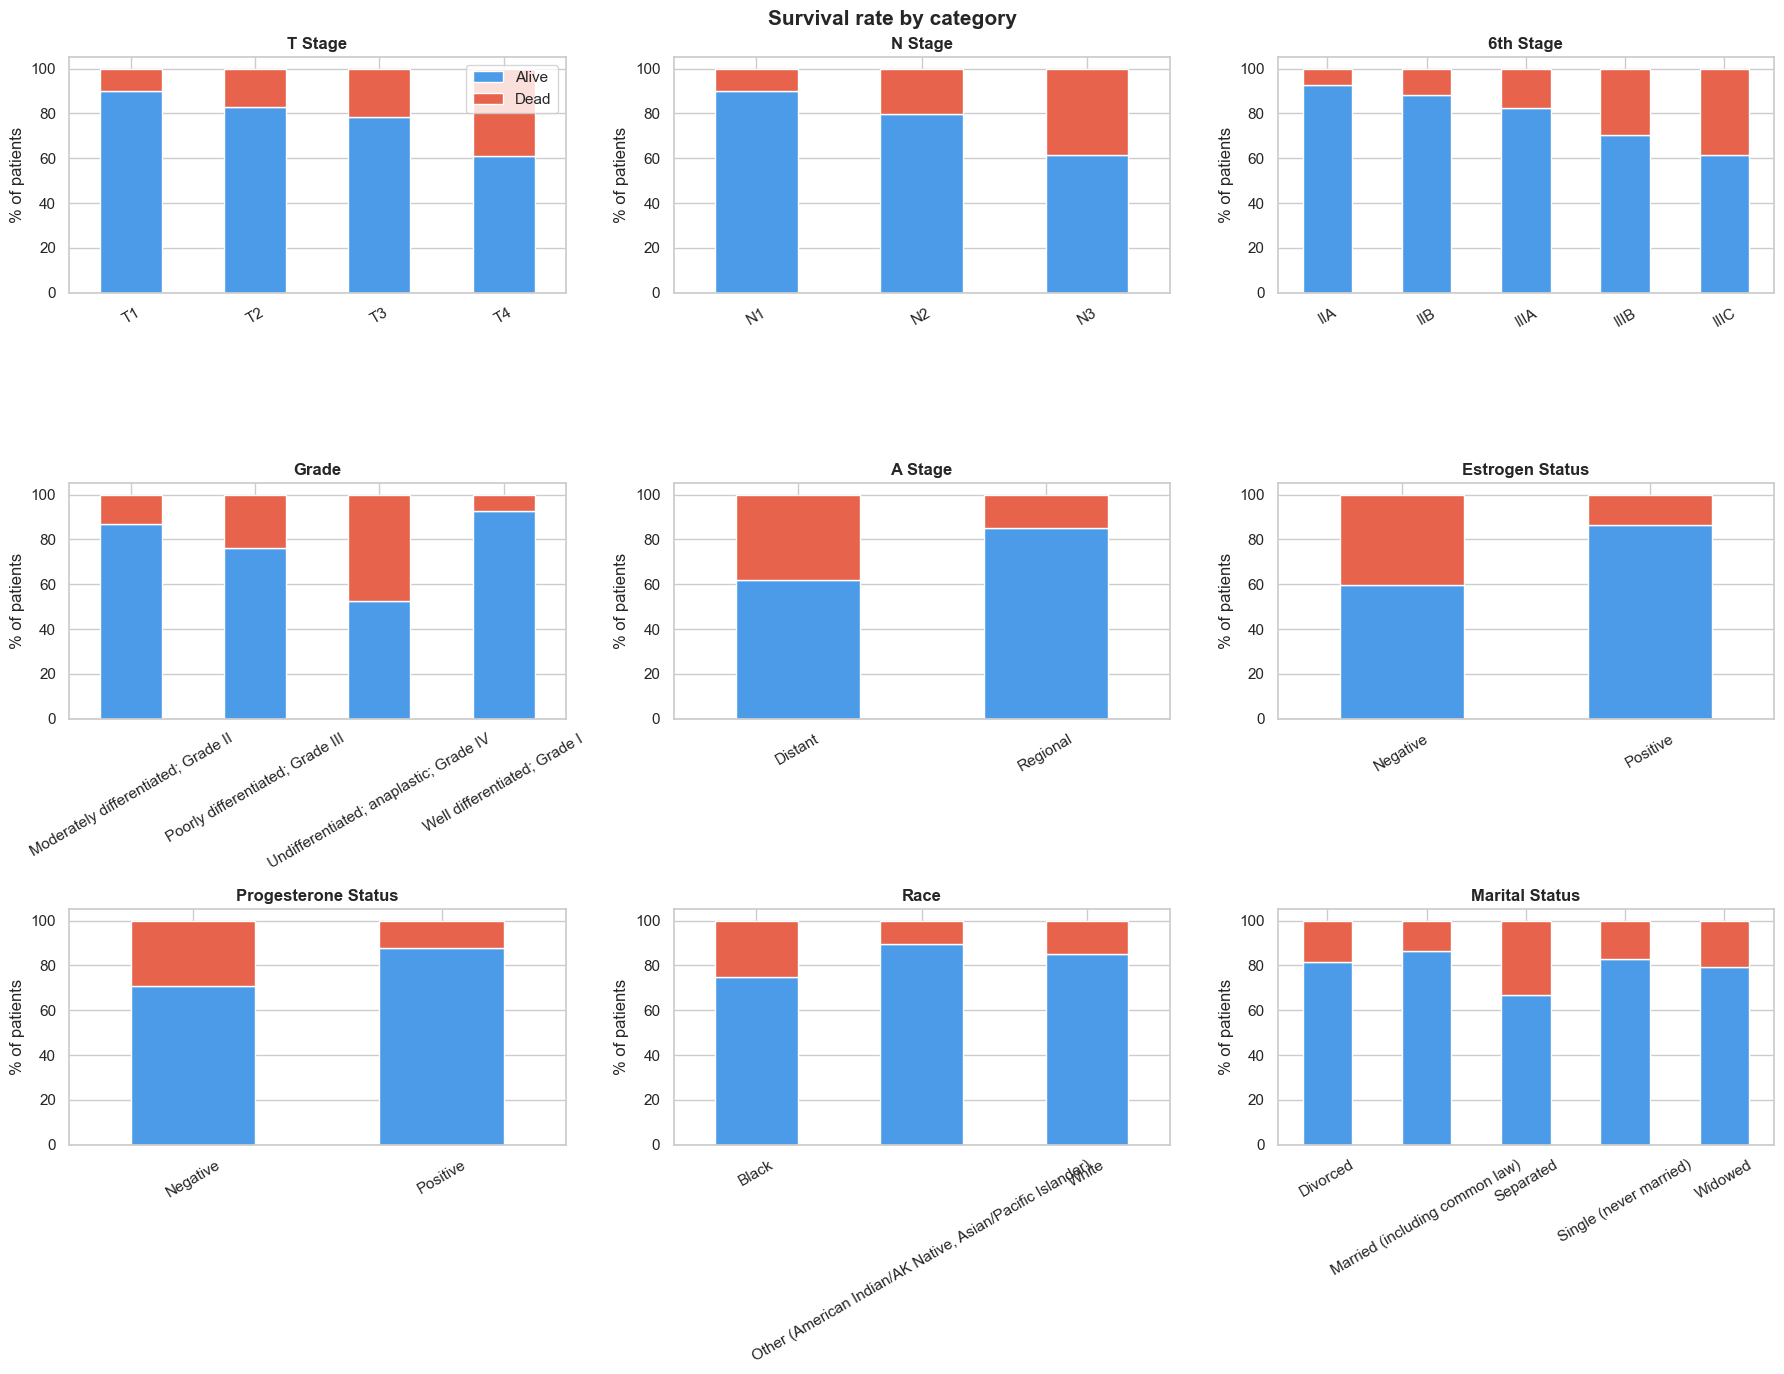

In [103]:
cat_cols = ['T Stage', 'N Stage', '6th Stage', 'Grade', 'A Stage',
            'Estrogen Status', 'Progesterone Status', 'Race', 'Marital Status']

fig, axes = plt.subplots(3, 3, figsize=(18, 14))

for ax, col in zip(axes.flatten(), cat_cols):
    rate = pd.crosstab(data[col], data['Status'], normalize='index') * 100
    rate.plot(kind='bar', stacked=True, color=['#4C9BE8', '#E8634C'], ax=ax, legend=False)
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('% of patients')
    ax.tick_params(axis='x', rotation=30)

axes[0, 0].legend(['Alive', 'Dead'])
plt.suptitle('Survival rate by category', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

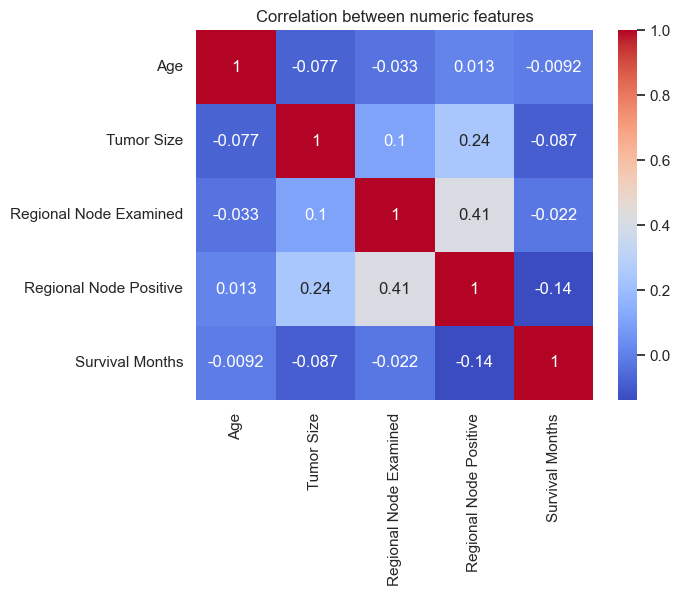

In [104]:
sns.heatmap(data.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation between numeric features')
plt.show()

Feature Engineering 

In [105]:
df = data.copy()

df['Node Ratio'] = df['Regional Node Positive'] / df['Regional Node Examined']
df = df.drop(columns='Survival Months')
df['Status'] = df['Status'].map({'Alive': 0, 'Dead': 1})
df = pd.get_dummies(df, drop_first=True, dtype=int)

df.head()

,Age,Tumor Size,Regional Node Examined,Regional Node Positive,Status,Node Ratio,"Race_Other (American Indian/AK Native, Asian/Pacific Islander)",Race_White,Marital Status_Married (including common law),Marital Status_Separated,...,6th Stage_IIB,6th Stage_IIIA,6th Stage_IIIB,6th Stage_IIIC,Grade_Poorly differentiated; Grade III,Grade_Undifferentiated; anaplastic; Grade IV,Grade_Well differentiated; Grade I,A Stage_Regional,Estrogen Status_Positive,Progesterone Status_Positive
0,43,40,19,11,0,0.578947,1,0,1,0,...,0,0,0,1,0,0,0,1,1,1
1,47,45,25,9,0,0.360000,1,0,1,0,...,0,1,0,0,0,0,0,1,1,1
2,67,25,4,1,1,0.250000,0,1,1,0,...,1,0,0,0,1,0,0,1,1,1
3,46,19,26,1,1,0.038462,0,1,0,0,...,0,0,0,0,0,0,0,1,1,1
4,63,35,21,5,1,0.238095,0,1,1,0,...,0,1,0,0,0,0,0,1,1,1


In [106]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns='Status')
y = df['Status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train.shape, X_test.shape)

(3218, 26) (805, 26)


3D Visualisation

In [107]:
%pip install --upgrade nbformat

Note: you may need to restart the kernel to use updated packages.


In [108]:
from sklearn.decomposition import PCA
import plotly.express as px

pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_train_scaled)

fig = px.scatter_3d(x=X_pca[:, 0], y=X_pca[:, 1], z=X_pca[:, 2],
                    color=y_train.map({0: 'Alive', 1: 'Dead'}),
                    color_discrete_map={'Alive': '#4C9BE8', 'Dead': '#E8634C'},
                    labels={'x': 'PC1', 'y': 'PC2', 'z': 'PC3', 'color': 'Status'},
                    title='3D PCA of patients', opacity=0.6)
fig.update_traces(marker_size=3)
fig.show()

print('Variance explained:', pca.explained_variance_ratio_.sum().round(2))

Variance explained: 0.32


In [109]:
fig = px.scatter_3d(data, x='Tumor Size', y='Regional Node Positive', z='Age',
                    color='Status',
                    color_discrete_map={'Alive': '#4C9BE8', 'Dead': '#E8634C'},
                    title='Tumour size, positive nodes and age by survival',
                    opacity=0.6)
fig.update_traces(marker_size=3)
fig.show()

In [110]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=3, random_state=42)
X_tsne = tsne.fit_transform(X_train_scaled)

fig = px.scatter_3d(x=X_tsne[:, 0], y=X_tsne[:, 1], z=X_tsne[:, 2],
                    color=y_train.map({0: 'Alive', 1: 'Dead'}),
                    color_discrete_map={'Alive': '#4C9BE8', 'Dead': '#E8634C'},
                    title='3D t-SNE of patients', opacity=0.6)
fig.update_traces(marker_size=3)
fig.show()

Machine learning 

In [111]:
# Imports and helper function 

from sklearn.metrics import (accuracy_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay)

results = []   # collects every model's scores for the final table

def evaluate(name, model):
    pred = model.predict(X_test_scaled)
    prob = model.predict_proba(X_test_scaled)[:, 1]

    scores = {'Model': name,
              'Accuracy': accuracy_score(y_test, pred),
              'Recall (Dead)': recall_score(y_test, pred),
              'F1 (Dead)': f1_score(y_test, pred),
              'ROC-AUC': roc_auc_score(y_test, prob)}

    results[:] = [r for r in results if r['Model'] != name]   # remove old row for this model
    results.append(scores)

    print(pd.Series(scores).drop('Model').astype(float).round(3))

    ConfusionMatrixDisplay.from_predictions(y_test, pred,
                                            display_labels=['Alive', 'Dead'], cmap='Blues')
    plt.title(name)
    plt.grid(False)
    plt.show()

Accuracy         0.847
Recall (Dead)    0.000
F1 (Dead)        0.000
ROC-AUC          0.500
dtype: float64


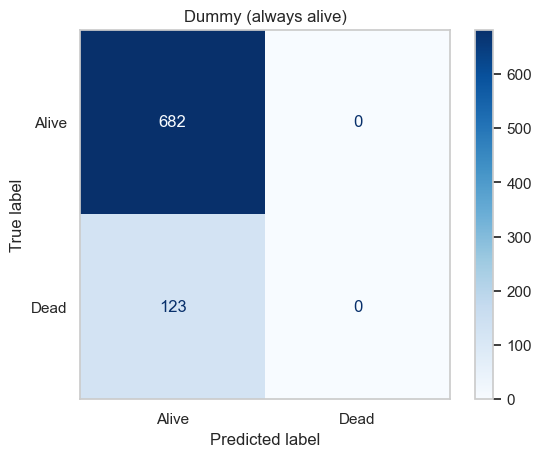

In [112]:
# Baseline

from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train_scaled, y_train)
evaluate('Dummy (always alive)', dummy)

Accuracy         0.737
Recall (Dead)    0.618
F1 (Dead)        0.418
ROC-AUC          0.749
dtype: float64


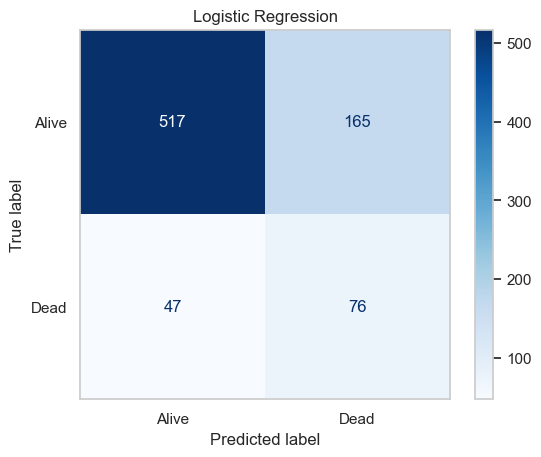

In [120]:
# Logistic Regression

from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(class_weight='balanced', max_iter=1000)
lr.fit(X_train_scaled, y_train)
evaluate('Logistic Regression', lr)

Accuracy         0.843
Recall (Dead)    0.073
F1 (Dead)        0.125
ROC-AUC          0.705
dtype: float64


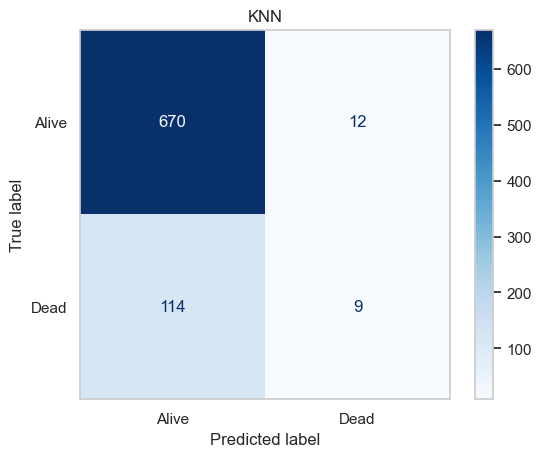

In [114]:
# KNN
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=15)
knn.fit(X_train_scaled, y_train)
evaluate('KNN', knn)

Accuracy         0.737
Recall (Dead)    0.545
F1 (Dead)        0.387
ROC-AUC          0.724
dtype: float64


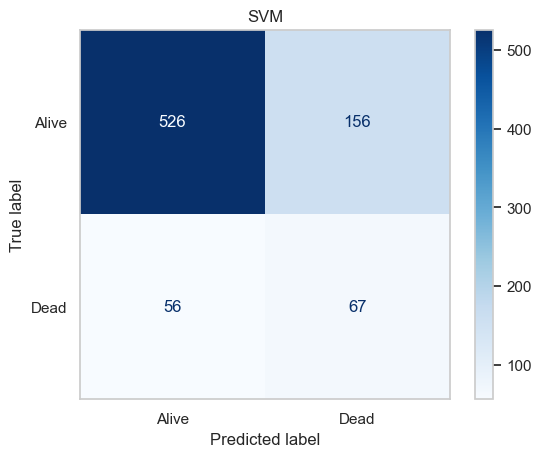

In [115]:
# SVM
from sklearn.svm import SVC

svm = SVC(class_weight='balanced', probability=True, random_state=42)
svm.fit(X_train_scaled, y_train)
evaluate('SVM', svm)

Accuracy         0.819
Recall (Dead)    0.398
F1 (Dead)        0.402
ROC-AUC          0.718
dtype: float64


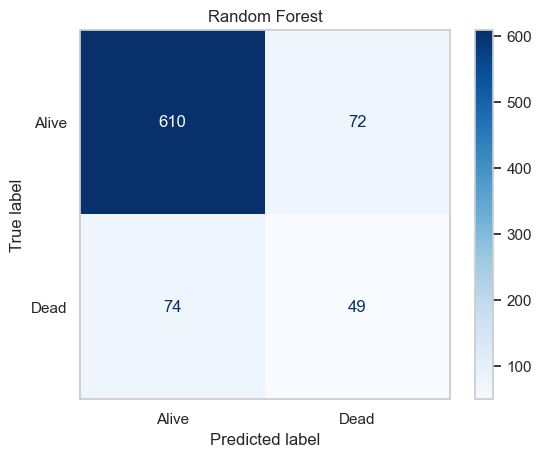

In [116]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(class_weight='balanced', min_samples_leaf=5, random_state=42)
rf.fit(X_train_scaled, y_train)
evaluate('Random Forest', rf)

Accuracy         0.754
Recall (Dead)    0.512
F1 (Dead)        0.389
ROC-AUC          0.694
dtype: float64


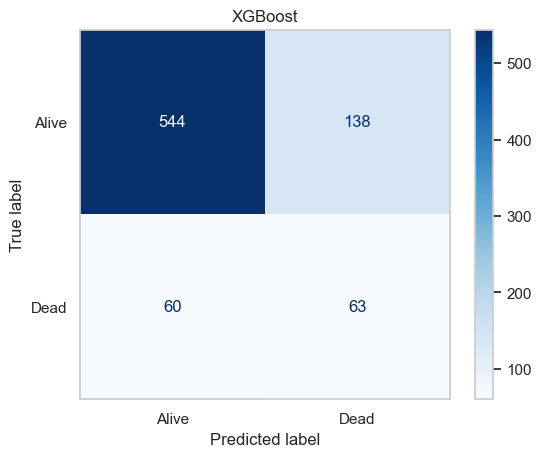

In [117]:
# XGBoost

from xgboost import XGBClassifier

xgb = XGBClassifier(scale_pos_weight=5.5, max_depth=5, n_estimators=200,
                    learning_rate=0.05, random_state=42)
xgb.fit(X_train_scaled, y_train)
evaluate('XGBoost', xgb)

Accuracy         0.846
Recall (Dead)    0.089
F1 (Dead)        0.151
ROC-AUC          0.691
dtype: float64


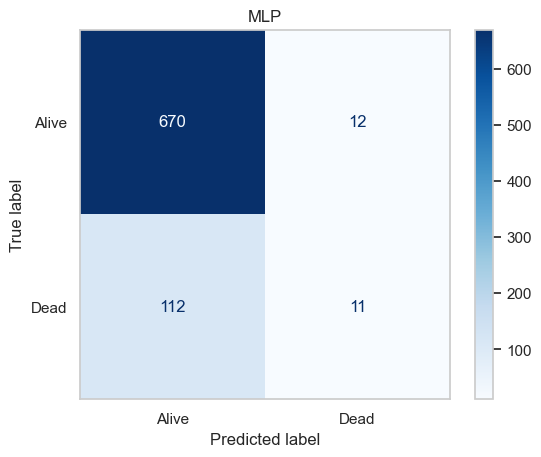

In [118]:
# MLP 

from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=1000,
                    early_stopping=True, random_state=42)
mlp.fit(X_train_scaled, y_train)
evaluate('MLP', mlp)

In [121]:
# Comparison Table 

pd.DataFrame(results).round(3).sort_values('ROC-AUC', ascending=False)

,Model,Accuracy,Recall (Dead),F1 (Dead),ROC-AUC
6,Logistic Regression,0.737,0.618,0.418,0.749
2,SVM,0.737,0.545,0.387,0.724
3,Random Forest,0.819,0.398,0.402,0.718
1,KNN,0.843,0.073,0.125,0.705
4,XGBoost,0.754,0.512,0.389,0.694
5,MLP,0.846,0.089,0.151,0.691
0,Dummy (always alive),0.847,0.000,0.000,0.500


Parameter Tuning 

In [122]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Best settings: {'C': 0.01}
CV AUC: 0.746
Accuracy         0.729
Recall (Dead)    0.585
F1 (Dead)        0.398
ROC-AUC          0.746
dtype: float64


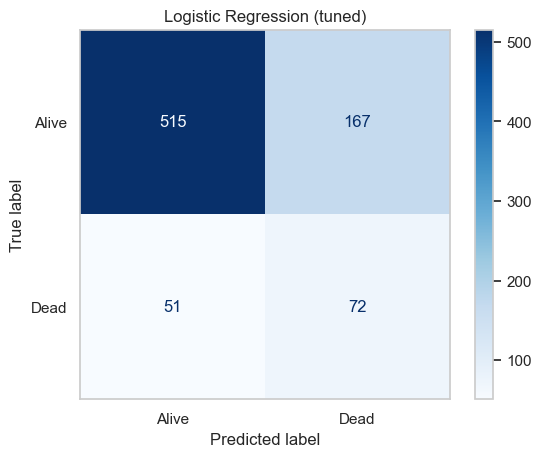

In [125]:
# Tuning logistic regression
params = {'C': [0.01, 0.1, 1, 10]}

grid_lr = GridSearchCV(LogisticRegression(class_weight='balanced', max_iter=1000),
                       params, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_lr.fit(X_train_scaled, y_train)

print('Best settings:', grid_lr.best_params_)
print('CV AUC:', round(grid_lr.best_score_, 3))
evaluate('Logistic Regression (tuned)', grid_lr.best_estimator_)

Best settings: {'C': 10, 'kernel': 'linear'}
CV AUC: 0.737
Accuracy         0.729
Recall (Dead)    0.553
F1 (Dead)        0.384
ROC-AUC          0.729
dtype: float64


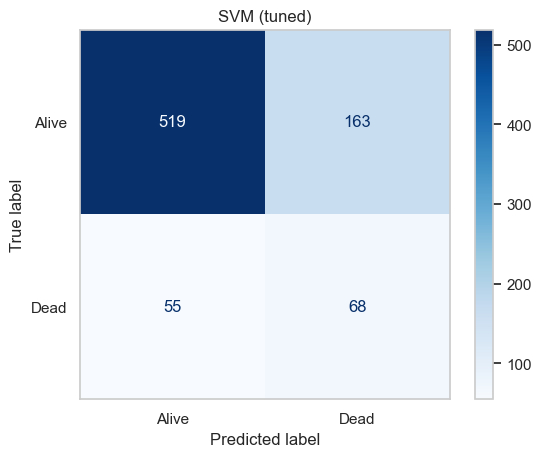

In [126]:
# Tuning SVM

params = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}

grid_svm = GridSearchCV(SVC(class_weight='balanced', probability=True, random_state=42),
                        params, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_svm.fit(X_train_scaled, y_train)

print('Best settings:', grid_svm.best_params_)
print('CV AUC:', round(grid_svm.best_score_, 3))
evaluate('SVM (tuned)', grid_svm.best_estimator_)

Best settings: {'max_depth': 5, 'min_samples_leaf': 10, 'n_estimators': 500}
CV AUC: 0.744
Accuracy         0.739
Recall (Dead)    0.537
F1 (Dead)        0.386
ROC-AUC          0.727
dtype: float64


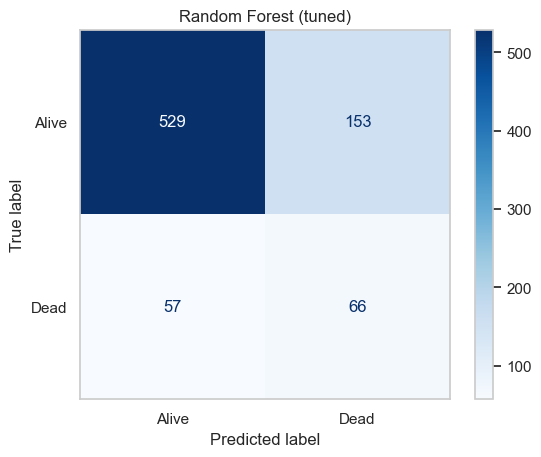

In [127]:
# Tuning Random Forest

params = {'n_estimators': [200, 500],
          'max_depth': [5, 10, None],
          'min_samples_leaf': [1, 5, 10]}

grid_rf = GridSearchCV(RandomForestClassifier(class_weight='balanced', random_state=42),
                       params, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_rf.fit(X_train_scaled, y_train)

print('Best settings:', grid_rf.best_params_)
print('CV AUC:', round(grid_rf.best_score_, 3))
evaluate('Random Forest (tuned)', grid_rf.best_estimator_)

Best settings: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100}
CV AUC: 0.751
Accuracy         0.719
Recall (Dead)    0.593
F1 (Dead)        0.392
ROC-AUC          0.736
dtype: float64


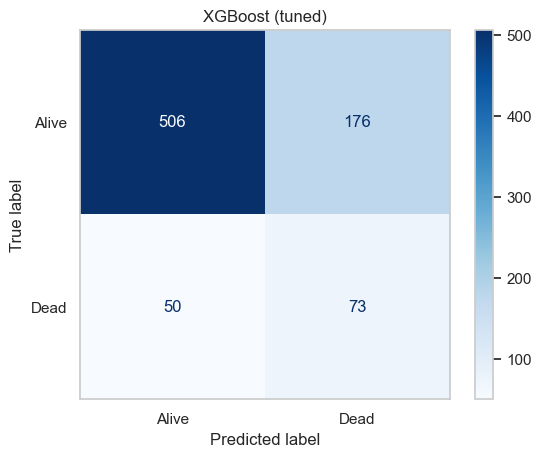

In [128]:
#Tuning XGBoost

params = {'max_depth': [2, 3, 4],
          'learning_rate': [0.01, 0.05, 0.1],
          'n_estimators': [100, 300]}

grid_xgb = GridSearchCV(XGBClassifier(scale_pos_weight=5.5, random_state=42),
                        params, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_xgb.fit(X_train_scaled, y_train)

print('Best settings:', grid_xgb.best_params_)
print('CV AUC:', round(grid_xgb.best_score_, 3))
evaluate('XGBoost (tuned)', grid_xgb.best_estimator_)

In [129]:
pd.DataFrame(results).round(3).sort_values('ROC-AUC', ascending=False)

,Model,Accuracy,Recall (Dead),F1 (Dead),ROC-AUC
6,Logistic Regression,0.737,0.618,0.418,0.749
7,Logistic Regression (tuned),0.729,0.585,0.398,0.746
10,XGBoost (tuned),0.719,0.593,0.392,0.736
8,SVM (tuned),0.729,0.553,0.384,0.729
9,Random Forest (tuned),0.739,0.537,0.386,0.727
2,SVM,0.737,0.545,0.387,0.724
3,Random Forest,0.819,0.398,0.402,0.718
1,KNN,0.843,0.073,0.125,0.705
4,XGBoost,0.754,0.512,0.389,0.694
5,MLP,0.846,0.089,0.151,0.691


XAI Techniques - Feature Importance, SHAP, & LIME 

In [ ]:
%pip install shap lime

In [131]:
best_xgb = grid_xgb.best_estimator_
best_lr = grid_lr.best_estimator_

X_train_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_df  = pd.DataFrame(X_test_scaled,  columns=X.columns)

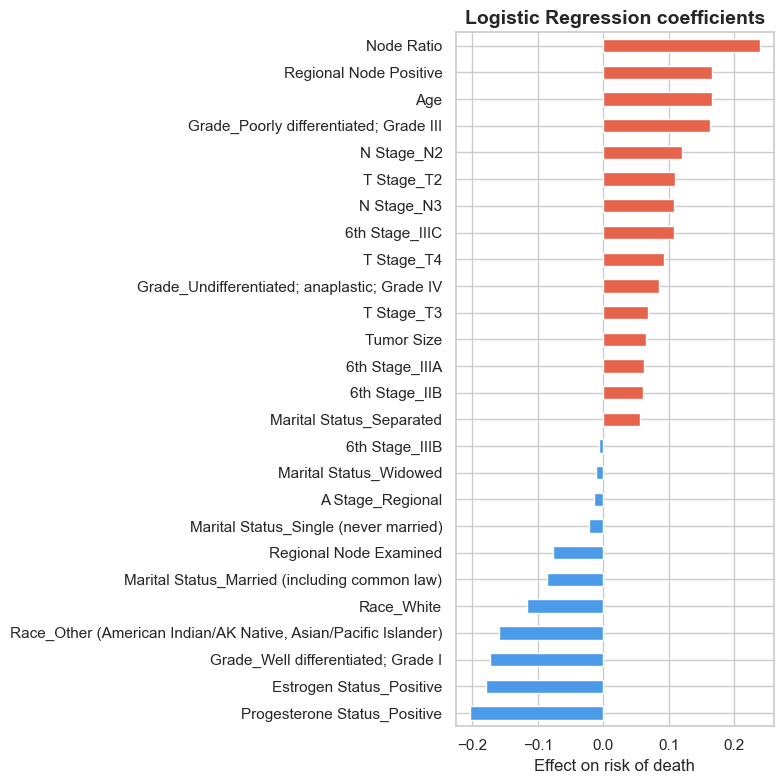

In [ ]:
# Feature Importance - Logistic Regression 
coef = pd.Series(best_lr.coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(8, 8))
coef.plot(kind='barh', color=['#4C9BE8' if c < 0 else '#E8634C' for c in coef])
plt.title('Logistic Regression coefficients', fontsize=14, fontweight='bold')
plt.xlabel('Effect on risk of death')
plt.tight_layout()
plt.show()

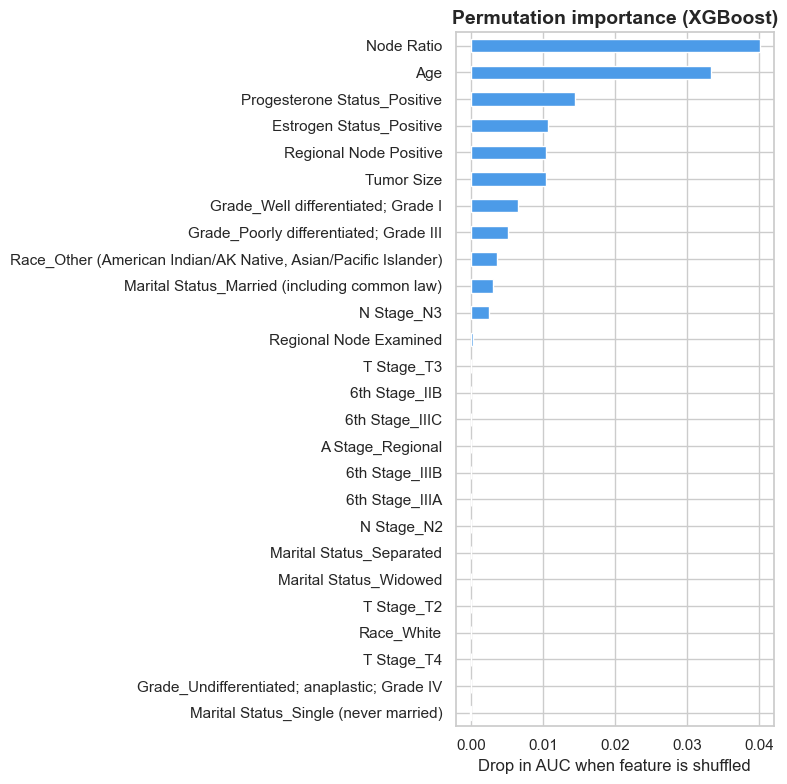

In [ ]:
# Feature Importance - XGBoost

from sklearn.inspection import permutation_importance

perm = permutation_importance(best_xgb, X_test_df, y_test, scoring='roc_auc',
                              n_repeats=10, random_state=42)
perm_imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()

plt.figure(figsize=(8, 8))
perm_imp.plot(kind='barh', color='#4C9BE8')
plt.title('Permutation importance (XGBoost)', fontsize=14, fontweight='bold')
plt.xlabel('Drop in AUC when feature is shuffled')
plt.tight_layout()
plt.show()

C:\Users\kasim\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


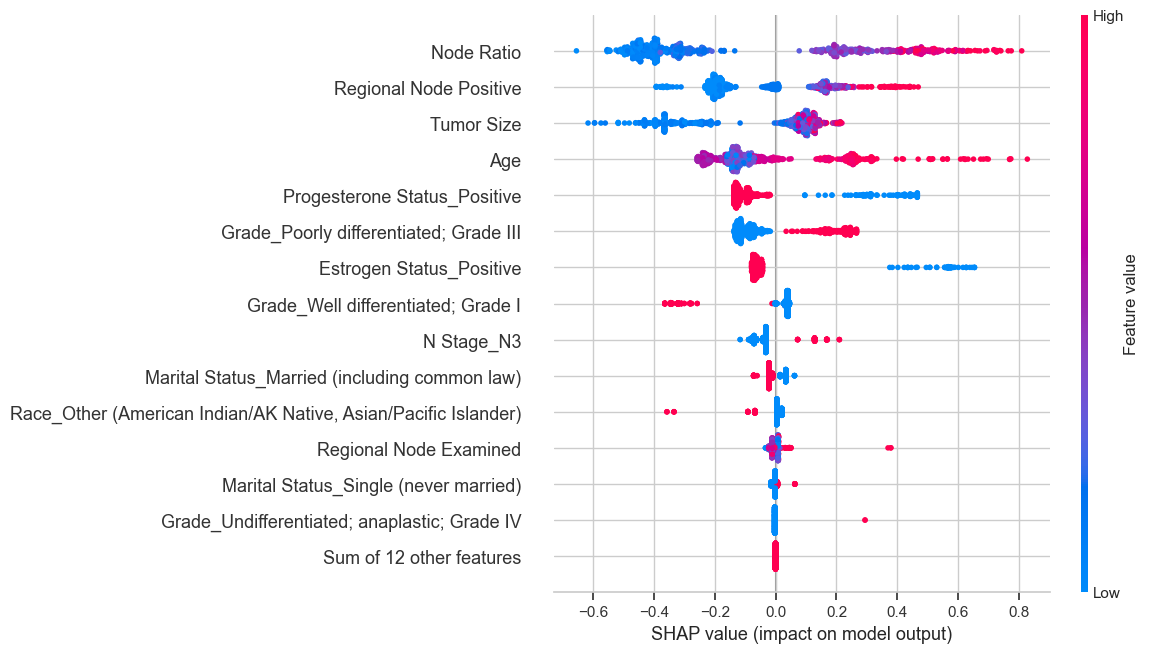

In [134]:
#SHAP - XGBoost

import shap

explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer(X_test_df)

shap.plots.beeswarm(shap_values, max_display=15)

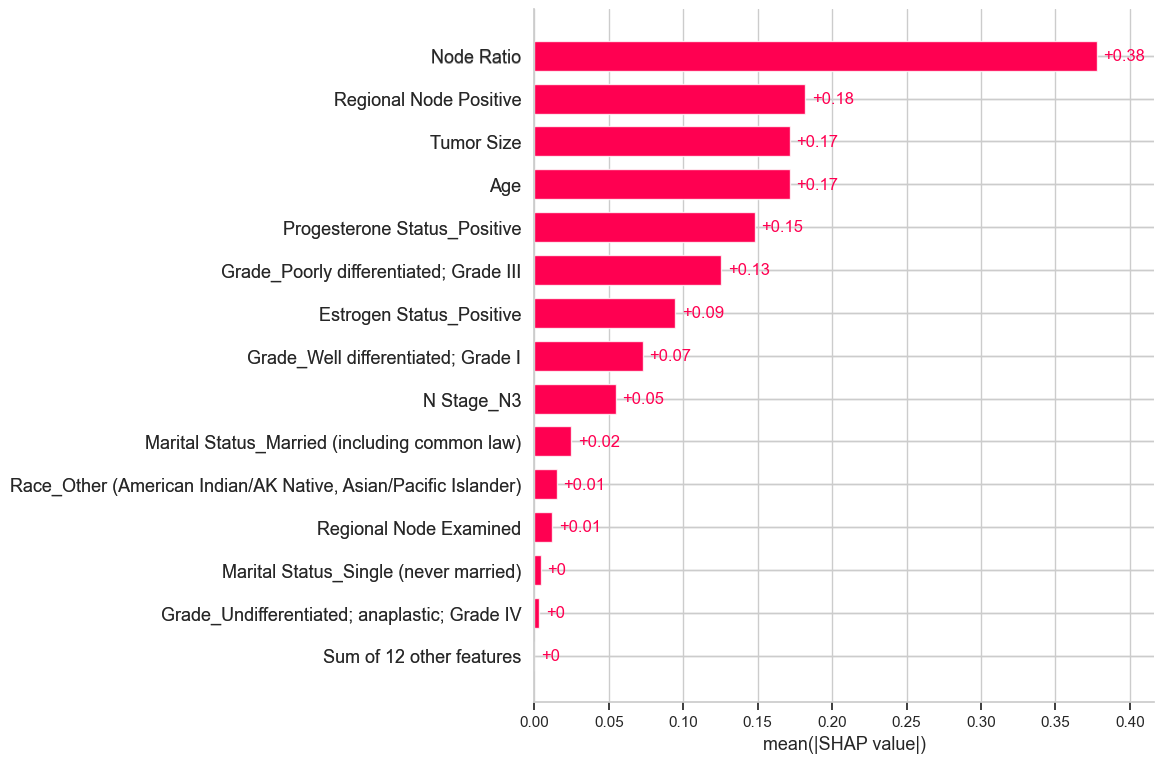

In [135]:
shap.plots.bar(shap_values, max_display=15)

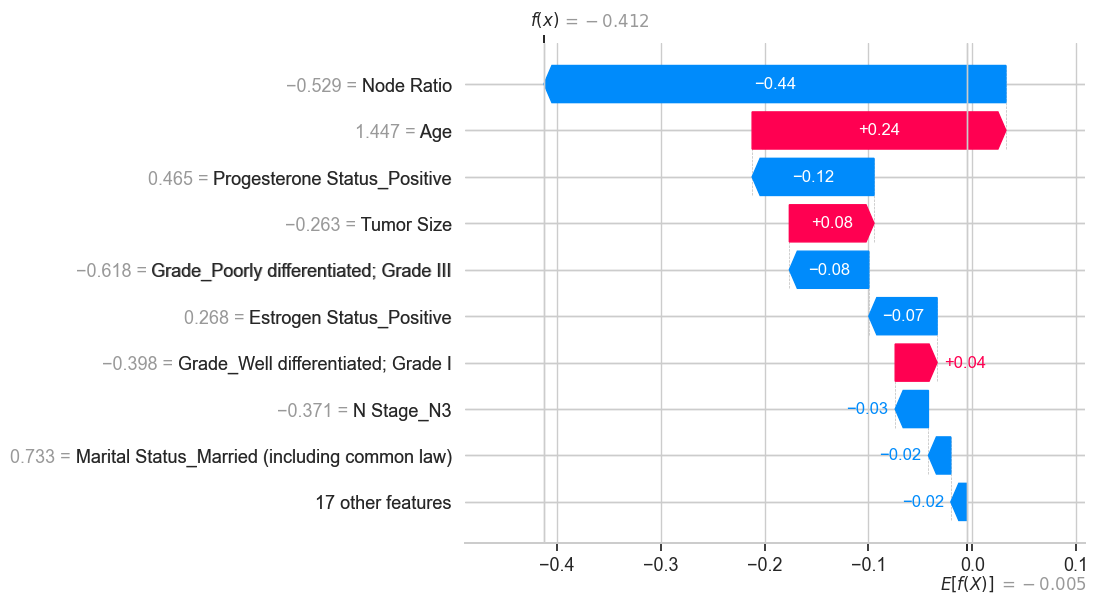

In [136]:
shap.plots.waterfall(shap_values[0])

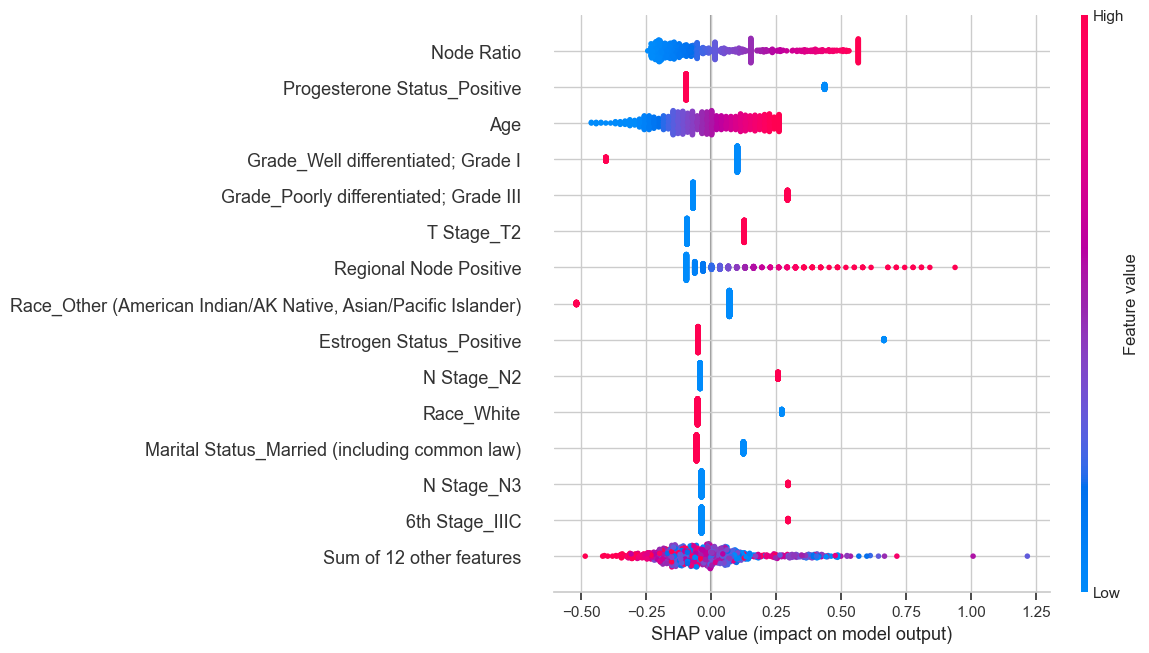

In [137]:
# SHAP - Logistic Regression 

lr_explainer = shap.LinearExplainer(best_lr, X_train_df)
lr_shap_values = lr_explainer(X_test_df)

shap.plots.beeswarm(lr_shap_values, max_display=15)

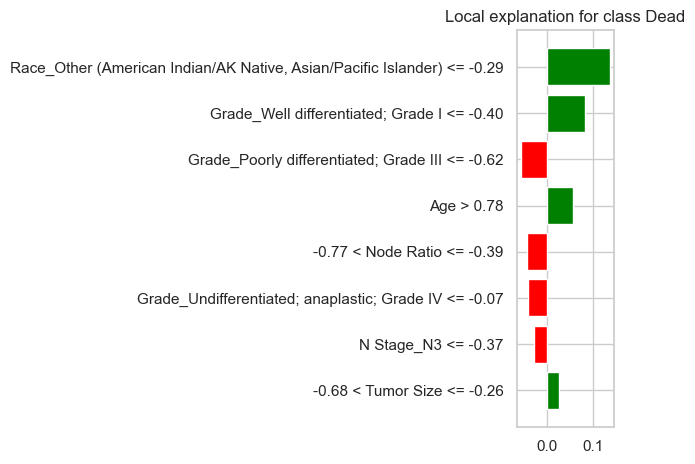

In [ ]:
#lime - XGBoost 
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(X_train_scaled,
                                      feature_names=X.columns.tolist(),
                                      class_names=['Alive', 'Dead'],
                                      mode='classification',
                                      random_state=42)

exp = lime_explainer.explain_instance(X_test_scaled[0], best_xgb.predict_proba, num_features=8)
exp.as_pyplot_figure()
plt.tight_layout()
plt.show()

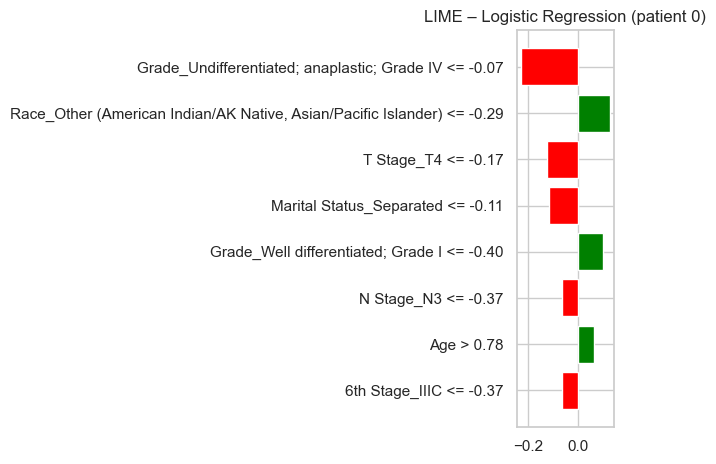

In [ ]:
# LIME - Logestic Regression
exp_lr = lime_explainer.explain_instance(X_test_scaled[0], best_lr.predict_proba, num_features=8)
exp_lr.as_pyplot_figure()
plt.title('LIME – Logistic Regression (patient 0)')
plt.tight_layout()
plt.show()